Day-2    -    Data Cleaning    -

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("../data/raw/train.csv",parse_dates=["date"])

In [12]:
df.head(5)

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [11]:
df['date']=pd.to_datetime(df['date'],errors="coerce")


In [13]:
df['store']=df['store'].astype("int32")
df['item']=df['item'].astype("int32")
df['sales']=pd.to_numeric(df['sales'],errors="coerce")


In [16]:
print(df.dtypes)

date     datetime64[us]
store             int32
item              int32
sales             int64
dtype: object


In [17]:
print("Missing values:")
print(df.isnull().sum())

print("\nMissing percentage:")
print(df.isnull().mean() * 100)

Missing values:
date     0
store    0
item     0
sales    0
dtype: int64

Missing percentage:
date     0.0
store    0.0
item     0.0
sales    0.0
dtype: float64


In [18]:
print("Before:", df.shape)

print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates(
    subset=["date", "store", "item"]
)

print("After:", df.shape)

Before: (913000, 4)
Duplicates: 0
After: (913000, 4)


In [19]:
print("Negative sales:", (df["sales"] < 0).sum())

print("Zero sales:", (df["sales"] == 0).sum())

print("Maximum sales:", df["sales"].max())

Negative sales: 0
Zero sales: 1
Maximum sales: 231


In [20]:
q1=df["sales"].quantile(0.25)
q2=df["sales"].quantile(0.75)

iqr=q2-q1

lower_bound=q1-1.5*iqr
upper_bound=q2+1.5*iqr


outliers = df[
    (df["sales"] < lower_bound) |
    (df["sales"] > upper_bound)
]

print("Q1:", q1)
print("Q3:", q2)
print("IQR:", iqr)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Outlier Count:", len(outliers))
print("Outlier Percentage:", len(outliers) / len(df) * 100)

Q1: 30.0
Q3: 70.0
IQR: 40.0
Lower Bound: -30.0
Upper Bound: 130.0
Outlier Count: 11967
Outlier Percentage: 1.3107338444687842


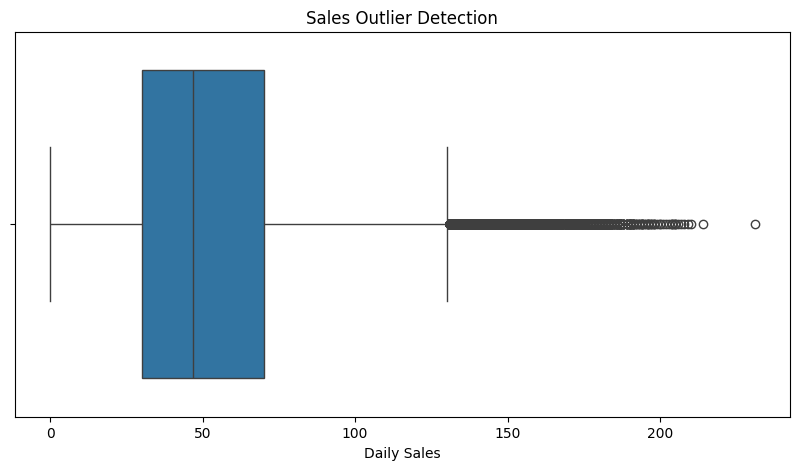

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["sales"])

plt.title("Sales Outlier Detection")
plt.xlabel("Daily Sales")

plt.show()

In [24]:
# Count unique combinations

combinations = df.groupby(
    ["store", "item"]
).size()

print("Total combinations:", len(combinations))

print("\nRecords per combination:")
print(combinations.describe())

print("\nMinimum records:", combinations.min())
print("Maximum records:", combinations.max())

Total combinations: 500

Records per combination:
count     500.0
mean     1826.0
std         0.0
min      1826.0
25%      1826.0
50%      1826.0
75%      1826.0
max      1826.0
dtype: float64

Minimum records: 1826
Maximum records: 1826


In [26]:
item_sales = df.groupby(
    ["date", "item"],
    as_index=False
)["sales"].sum()

item_sales.head()

,date,item,sales
0,2013-01-01,1,133
1,2013-01-01,2,327
2,2013-01-01,3,172
3,2013-01-01,4,102
4,2013-01-01,5,83


In [27]:
store_sales=df.groupby([df["date"], df["store"]], as_index=False)["sales"].sum()

In [28]:
daily_sales=df.groupby([df["date"]], as_index=False)["sales"].sum()

In [29]:
import os
os.makedirs("../data/processed", exist_ok=True)

# Main cleaned dataset
df = df.sort_values(
    ["store", "item", "date"]
).reset_index(drop=True)

df.to_csv(
    "../data/processed/train_clean.csv",
    index=False
)

# Aggregated datasets
item_sales.to_csv(
    "../data/processed/item_sales.csv",
    index=False
)

store_sales.to_csv(
    "../data/processed/store_sales.csv",
    index=False
)

daily_sales.to_csv(
    "../data/processed/daily_sales.csv",
    index=False
)

print("All datasets saved successfully!")

All datasets saved successfully!
